<a href="https://colab.research.google.com/github/sanketkandalkar46-del/dsa-pp/blob/main/Classification_using_Decision_Tree_and_Na%C3%AFve_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1: Import Required Libraries

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Step 2: Load the Dataset

In [15]:
titanic = pd.read_csv('sample_data/titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Step 3: Data Preparation

In [16]:

# Reading the first and last n rows of a dataset
print("First rows:\n", titanic.head())
print("Last rows:\n", titanic.tail())

# Checking the dimensions of the data frame
print("Dimensions:", titanic.shape)

# Printing information about a DataFrame
titanic.info()

# Providing descriptive statistics for dataset
print(titanic.describe(include='all'))

# Checking for missing values in the data
print("Missing values:\n", titanic.isnull().sum())

# Finding duplicate records
print("Duplicates:", titanic.duplicated().sum())

First rows:
    PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN 

Step 4: Data Preprocessing

In [17]:
# Handling missing values
titanic['Age'] = titanic['Age'].fillna(titanic['Age'].mean())

# Checking number of unique values for each column
print(titanic.nunique())

# Dropping features containing unique values and unnecessary columns
titanic.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'], inplace=True, errors='ignore')

# Converting categorical variables into numerical values
le = LabelEncoder()
titanic['Sex'] = le.fit_transform(titanic['Sex'])
if 'Embarked' in titanic.columns:
    titanic['Embarked'] = titanic['Embarked'].fillna(titanic['Embarked'].mode()[0])
    titanic['Embarked'] = le.fit_transform(titanic['Embarked'])

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             89
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64


Step 5: Exploratory Data Analysis (EDA)

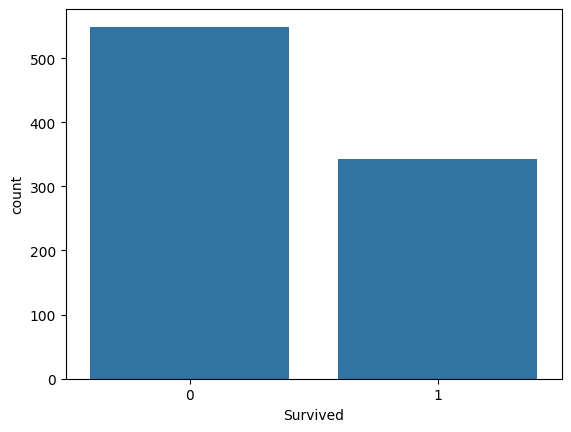

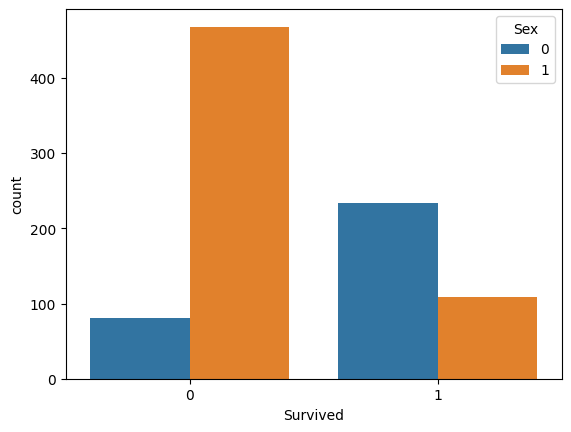

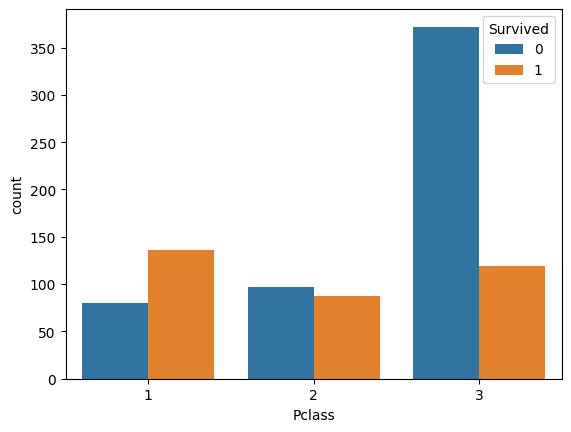

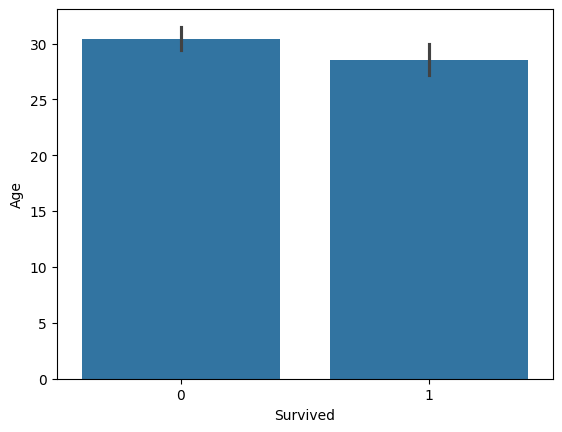

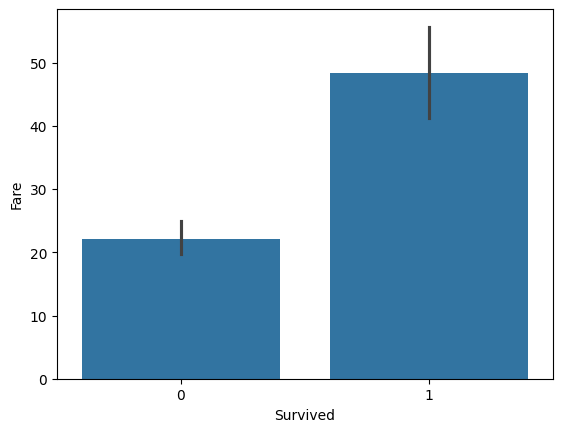

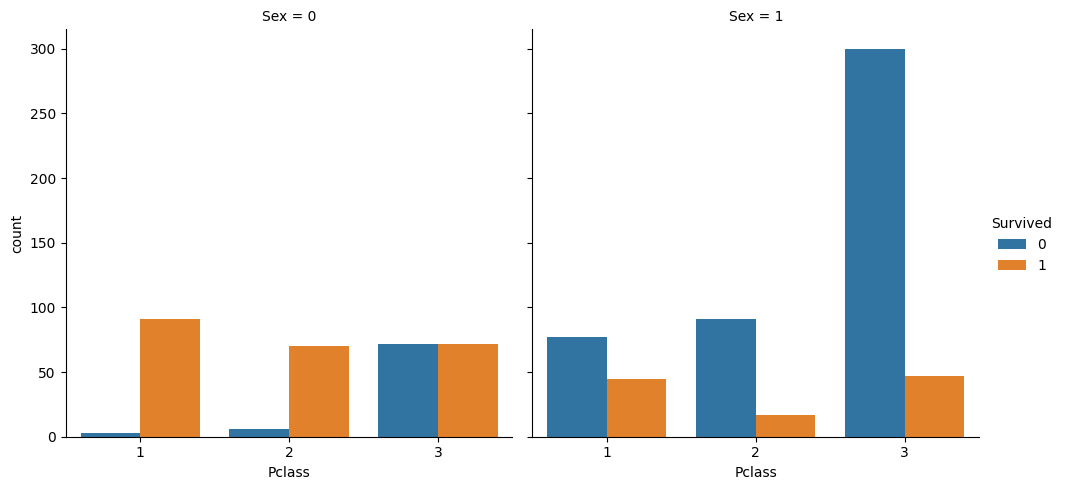

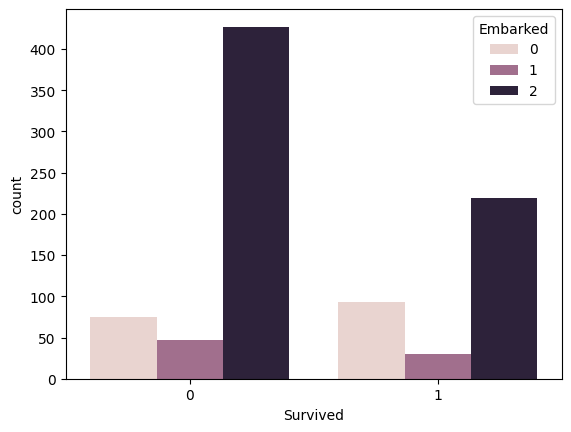

In [18]:
# Check how many passengers survived
sns.countplot(x=titanic['Survived'])
plt.show()

# Compare survival by gender
sns.countplot(x=titanic['Survived'], hue=titanic['Sex'])
plt.show()

# Compare survival by passenger class
sns.countplot(x=titanic['Pclass'], hue=titanic['Survived'])
plt.show()

# Analyze the relationship between age and survival
sns.barplot(x=titanic['Survived'], y=titanic['Age'])
plt.show()

# Analyze fare and survival
sns.barplot(x=titanic['Survived'], y=titanic['Fare'])
plt.show()

# Survival by Gender and Passenger Class
sns.catplot(x="Pclass", hue="Survived", col="Sex", data=titanic, kind="count")
plt.show()

# Survival by Embarkation Port
if 'Embarked' in titanic.columns:
    sns.countplot(x=titanic['Survived'], hue=titanic['Embarked'])
    plt.show()

Step 6: Extract Features and Target

In [19]:
X = titanic.drop("Survived", axis=1)
y = titanic['Survived']

Step 7: Train-Test Split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Step 8: Feature Scaling

In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Step 9: Decision Tree Classifier

Decision Tree Accuracy: 0.7988826815642458
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.91      0.84       105
           1       0.84      0.64      0.72        74

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.80      0.80      0.79       179

Confusion Matrix:
 [[96  9]
 [27 47]]


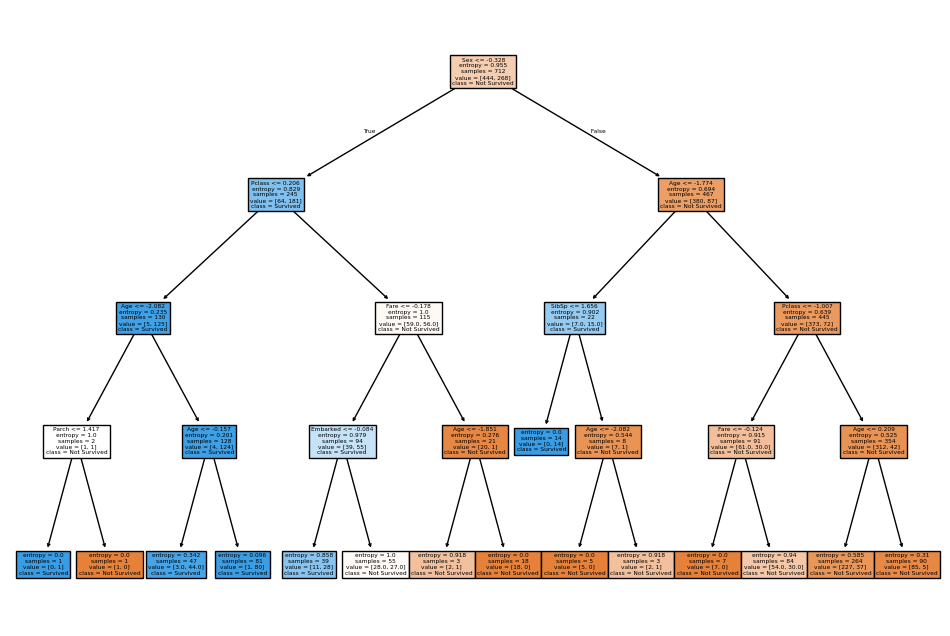

In [22]:
# Build the Classification Model
dt = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
dt.fit(X_train_scaled, y_train)

# Make Predictions
y_pred_dt = dt.predict(X_test_scaled)

# Evaluate the Model
print('Decision Tree Accuracy:', accuracy_score(y_test, y_pred_dt))
print('Classification Report:\n', classification_report(y_test, y_pred_dt))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_dt))

# Plot the Decision Tree
plt.figure(figsize=(12, 8))
plot_tree(dt, feature_names=X.columns, class_names=['Not Survived', 'Survived'], filled=True)
plt.show()

Step 10: Naïve Bayes Classifier

In [23]:
# Build the Classification Model
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

# Make Predictions
y_pred_nb = nb.predict(X_test_scaled)

# Evaluate the Model
print('Naïve Bayes Accuracy:', accuracy_score(y_test, y_pred_nb))
print('Classification Report:\n', classification_report(y_test, y_pred_nb))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_nb))

Naïve Bayes Accuracy: 0.776536312849162
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.78      0.80       105
           1       0.71      0.77      0.74        74

    accuracy                           0.78       179
   macro avg       0.77      0.78      0.77       179
weighted avg       0.78      0.78      0.78       179

Confusion Matrix:
 [[82 23]
 [17 57]]


Step 11: Handling Imbalanced Data using SMOTE

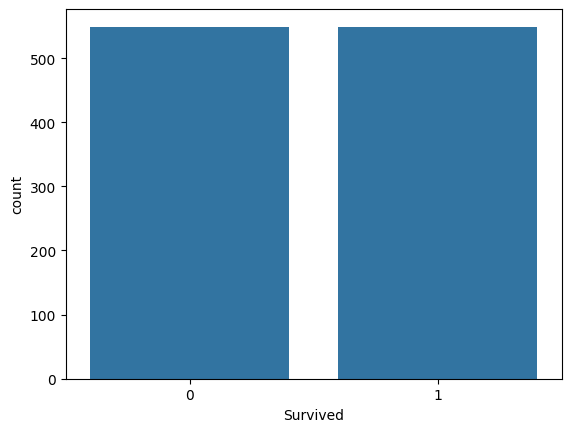

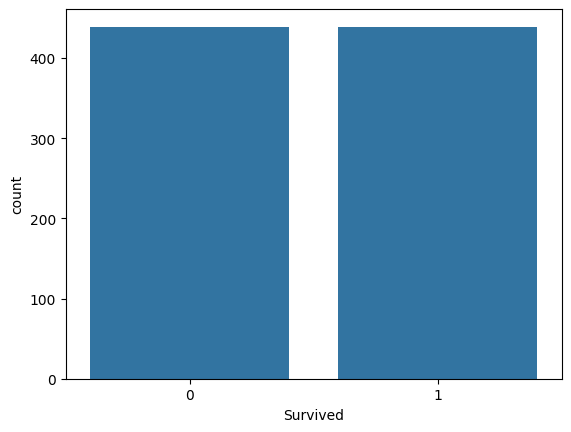

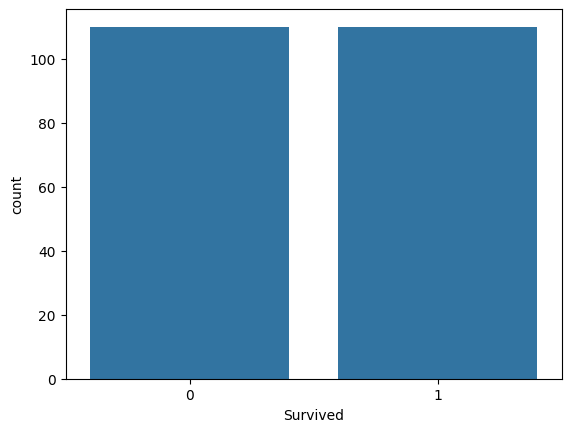

Confusion Matrix:
 [[91 19]
 [23 87]]
Accuracy score: 0.8090909090909091
Precision score: 0.8207547169811321
Recall score: 0.7909090909090909
F-beta score: 0.8055555555555556
Classification report:
               precision    recall  f1-score   support

           0       0.80      0.83      0.81       110
           1       0.82      0.79      0.81       110

    accuracy                           0.81       220
   macro avg       0.81      0.81      0.81       220
weighted avg       0.81      0.81      0.81       220



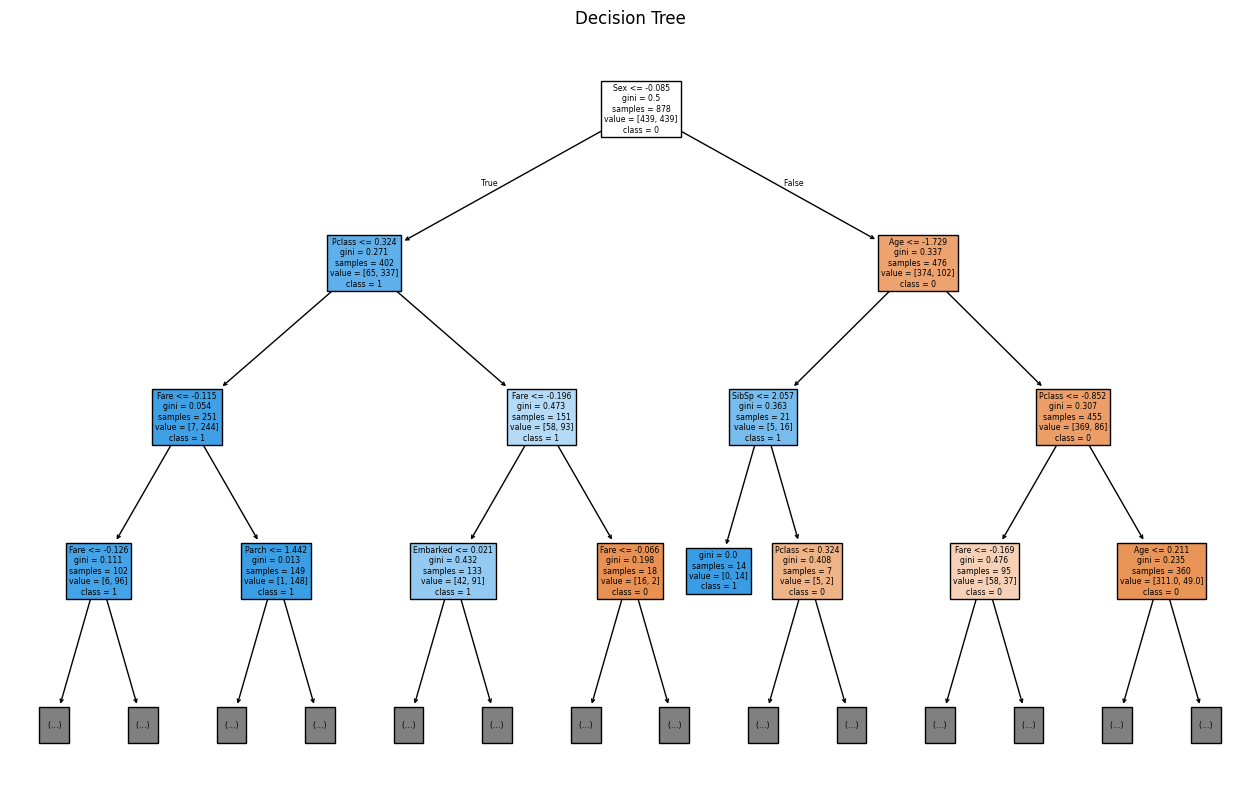

In [24]:

from imblearn.over_sampling import SMOTE
from sklearn.metrics import precision_score, recall_score, fbeta_score

# Resampling data
oversample = SMOTE(random_state=42)
X_sampled, y_sampled = oversample.fit_resample(X, y)

sns.countplot(x=y_sampled)
plt.show()

# Splitting dataset into training and test sets after SMOTE
X_train_sm, X_test_sm, y_train_sm, y_test_sm = train_test_split(
    X_sampled, y_sampled, train_size=0.8, random_state=42, stratify=y_sampled
)

sns.countplot(x=y_train_sm)
plt.show()

sns.countplot(x=y_test_sm)
plt.show()

# Feature Scaling
scaler_sm = StandardScaler()
X_train_scaled_sm = scaler_sm.fit_transform(X_train_sm)
X_test_scaled_sm = scaler_sm.transform(X_test_sm)

# Decision Tree Classifier on Resampled Data
classifier = DecisionTreeClassifier(random_state=42)
classifier.fit(X_train_scaled_sm, y_train_sm)

# Predicting test set results
y_pred_sm = classifier.predict(X_test_scaled_sm)

# Evaluate the Model
print('Confusion Matrix:\n', confusion_matrix(y_test_sm, y_pred_sm))
print('Accuracy score:', accuracy_score(y_test_sm, y_pred_sm))
print('Precision score:', precision_score(y_test_sm, y_pred_sm))
print('Recall score:', recall_score(y_test_sm, y_pred_sm))
print('F-beta score:', fbeta_score(y_test_sm, y_pred_sm, beta=1))
print('Classification report:\n', classification_report(y_test_sm, y_pred_sm))

# Visualize Decision Tree
plt.figure(figsize=(16, 10))
plot_tree(decision_tree=classifier, feature_names=X.columns, class_names=['0', '1'], filled=True, max_depth=3)
plt.title('Decision Tree')
plt.savefig('Decision Tree.png')
plt.show()